# Car Price Analysis – Exploratory Data Analysis

## Data Card
## Used Car Price Analysis – Car Details From Car Dekho

### 1. Dataset Name
**Car Details From Car Dekho**

### 2. Dataset Source
- **Source:** Kaggle
- **Original Platform:** CarDekho
- **File Name:** CAR DETAILS FROM CAR DEKHO.csv
- **File Format:** CSV (Comma-Separated Values)

### 3. Dataset Overview
The Car Details From Car Dekho dataset contains information about used cars and their selling prices. It provides details about car models, manufacturing years, selling prices, kilometers driven, fuel types, seller categories, transmission systems, and ownership history.

This dataset can be used to explore used car market trends and understand how different car characteristics are associated with selling prices.

### 4. Dataset Size
The dataset contains the following information:

- **Total Rows:** 4,340
- **Total Columns:** 8
- **Numerical Columns:** 3
- **Categorical Columns:** 5
- **Manufacturing Year Range:** 1992–2020

### 5. What Does One Row Represent?
Each row represents one car record containing information about its model, manufacturing year, selling price, kilometers driven, fuel type, seller type, transmission, and ownership status.

### 6. Features Description

| Column Name | Data Type | Description |
|---|---|---|
| name | Categorical | Name and model of the car |
| year | Numerical | Year in which the car was manufactured |
| selling_price | Numerical | Selling price of the car |
| km_driven | Numerical | Total distance driven by the car in kilometers |
| fuel | Categorical | Type of fuel used by the car |
| seller_type | Categorical | Category of the seller |
| transmission | Categorical | Type of transmission (Manual or Automatic) |
| owner | Categorical | Previous ownership status of the car |

### 7. Analysis Objective
The main objective of this project is to perform Exploratory Data Analysis (EDA) on used car data to identify patterns, trends, and relationships between different car features and selling prices.

The analysis will focus on understanding how manufacturing year, kilometers driven, fuel type, transmission, seller type, and ownership history are associated with car prices.

### 8. Data Quality Overview
An initial inspection of the dataset shows:

- **Missing Values:** 0
- **Duplicate Rows:** 763
- **Unique Car Names:** 1,491

Duplicate records will be investigated during the data-cleaning process before deciding whether to remove them.

### 9. Dataset Limitations
The dataset has some limitations:

- It does not provide detailed information about the physical condition of cars.
- It does not include accident history.
- It does not provide engine specifications such as horsepower or engine size.
- It does not contain exact geographical locations of car records.
- It does not include the actual date when each car was listed or sold.

These limitations should be considered when interpreting the analysis results.

### 10. Expected Outcome
The analysis is expected to identify important patterns in used car prices, compare prices across different car categories, and explore the relationship between car characteristics and selling prices.

The findings will be presented through statistical summaries, visualizations, and an interactive Streamlit dashboard.

In [35]:
pip install numpy pandas seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [37]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Step # 01 Understand the Data

In [38]:
carData = pd.read_csv('CARDataSet.csv')
print("Dataset Shape:", carData.shape)

Dataset Shape: (4340, 8)


### Dataset Shape

The dataset contains **4,340 rows and 8 columns**.

- **Rows:** Each row represents a car listing in the dataset.
- **Columns:** Each column represents a feature or attribute of the car.

The dataset contains enough records and features to perform exploratory data analysis (EDA) and investigate used car prices and related factors.

In [39]:
carData.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


The first five rows give a preview of the dataset. They show the car name, manufacturing year, selling price, kilometres driven, fuel type, seller type, transmission, and owner category.

In [40]:
carData.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner
4339,Renault KWID RXT,2016,225000,40000,Petrol,Individual,Manual,First Owner


The last five rows show the final records in the original dataset. This helps confirm how the data is arranged at the end of the file.

In [41]:
carData.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='str')

The output lists all eight column names. These columns describe the car model and its main characteristics, which will be explored in the analysis.

In [42]:
carData.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


The statistical summary shows the count, mean, standard deviation, minimum, quartiles, and maximum for numerical columns. It gives an initial view of the ranges and spread of car years, selling prices, and kilometres driven.

In [43]:
carData.info()

<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB


The output confirms the dataset structure and data types. The dataset has 4,340 rows and 8 columns, with no null values shown in the non-null counts.

## Step # 2: Research Questions
The following 8 questions will be answered through Exploratory Data
Analysis (EDA). These questions include univariate analysis, bivariate
analysis, and group comparison.
### Univariate Analysis
1. Which car models appear most frequently in the dataset?
2. Which fuel type is most commonly used?
3. Which transmission type is most popular?
### Bivariate Analysis
4. How is manufacturing year associated with car selling prices?
5. Is there a relationship between kilometers driven and selling price?
6. Which fuel type has the highest average selling price?
### Group Comparison
7. How does selling price differ between first-owner and second-owner
   cars?
8. Do automatic cars have higher average selling prices than manual
   cars?
### Objective
The objective of these questions is to understand the distribution of
car models, fuel types, and transmission types, and explore how
manufacturing year, kilometers driven, fuel type, ownership, and
transmission are associated with car selling prices.

## Step # 03 Clean the data
### Missing values

In [73]:
carDataSet = carData.copy()

Using .copy() creates an independent DataFrame, which is useful for performing data cleaning and preprocessing safely

In [74]:
carDataSet.dtypes

name               str
year             int64
selling_price    int64
km_driven        int64
fuel               str
seller_type        str
transmission       str
owner              str
dtype: object

The data types are appropriate for this dataset: year, selling_price, and km_driven are numeric, while name, fuel, seller_type, transmission, and owner are text/category fields. The year column should remain an integer because it contains only a manufacturing year, not a complete date; converting it to datetime is unnecessary. No data-type correction is required.

In [ ]:
carDataSet.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

The missing-value count is zero for every column. Therefore, there are no missing values to drop or fill in this dataset.

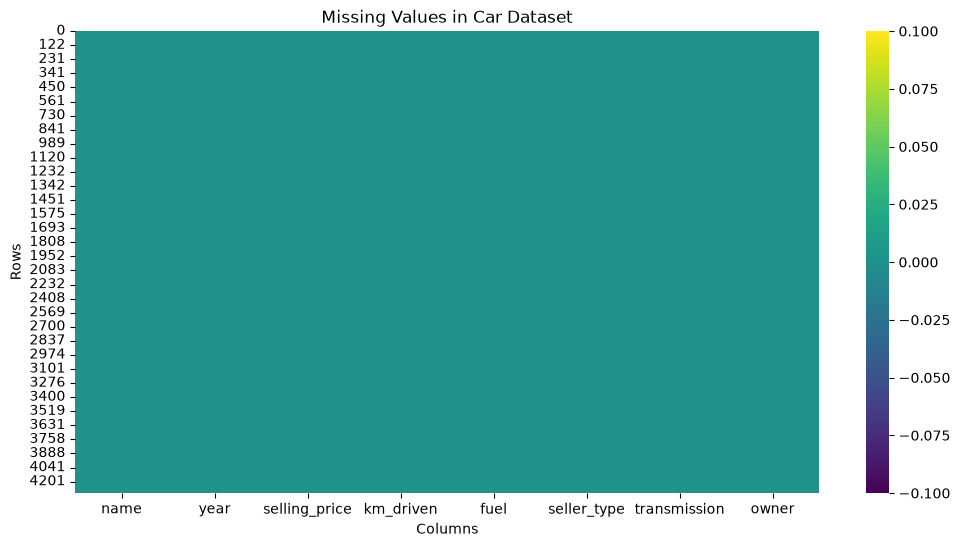

In [94]:

plt.figure(figsize=(12, 6))

sns.heatmap(
    carDataSet.isnull(),
    cmap="viridis",
    cbar=True
)

plt.title("Missing Values in Car Dataset")
plt.xlabel("Columns")
plt.ylabel("Rows")

plt.show()


The graph confirms that all eight columns have zero missing values. Since no missing values are present, filling or dropping rows for missing data is unnecessary.

### Duplicate

In [46]:
carDataSet.duplicated().sum()

np.int64(763)

The output shows 763 exact duplicate rows in the original dataset. These repeated records could count the same car information more than once, so they should be inspected before removal.

In [79]:
duplicates = carDataSet[carDataSet.duplicated()]
display(duplicates.head(10))

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
13,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
14,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
15,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
16,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
17,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
18,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner
19,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner
20,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner
21,Hyundai Creta 1.6 VTVT S,2015,850000,25000,Petrol,Individual,Manual,First Owner
22,Maruti Celerio Green VXI,2017,365000,78000,CNG,Individual,Manual,First Owner


The preview displays examples of the repeated rows. They match records already present in the dataset, so removing exact duplicates is appropriate to avoid counting identical records multiple times.

In [80]:
carDataSet = carDataSet.drop_duplicates()

print("Shape after removing duplicates:", carDataSet.shape)

Shape after removing duplicates: (3577, 8)


After removing exact duplicate rows, the dataset contains 3,577 rows and all 8 columns. The column information is retained while repeated records are removed.

In [81]:
print("Duplicates after cleaning:", carDataSet.duplicated().sum())

Duplicates after cleaning: 0


The duplicate count is now zero. This confirms that no exact duplicate rows remain after cleaning.

### Numerical & Categorical Column

In [82]:
numerical_columns = carDataSet.select_dtypes(include=["number"]).columns
categorical_columns = carDataSet.select_dtypes(include=["str", "object"]).columns

print("Numerical Columns:", numerical_columns)
print("Categorical Columns:", categorical_columns)


Numerical Columns: Index(['year', 'selling_price', 'km_driven'], dtype='str')
Categorical Columns: Index(['name', 'fuel', 'seller_type', 'transmission', 'owner'], dtype='str')


The dataset has three numerical columns (year, selling_price, and km_driven) and five categorical columns (name, fuel, seller_type, transmission, and owner). This classification helps select suitable statistical methods and visualizations.

### Outliers

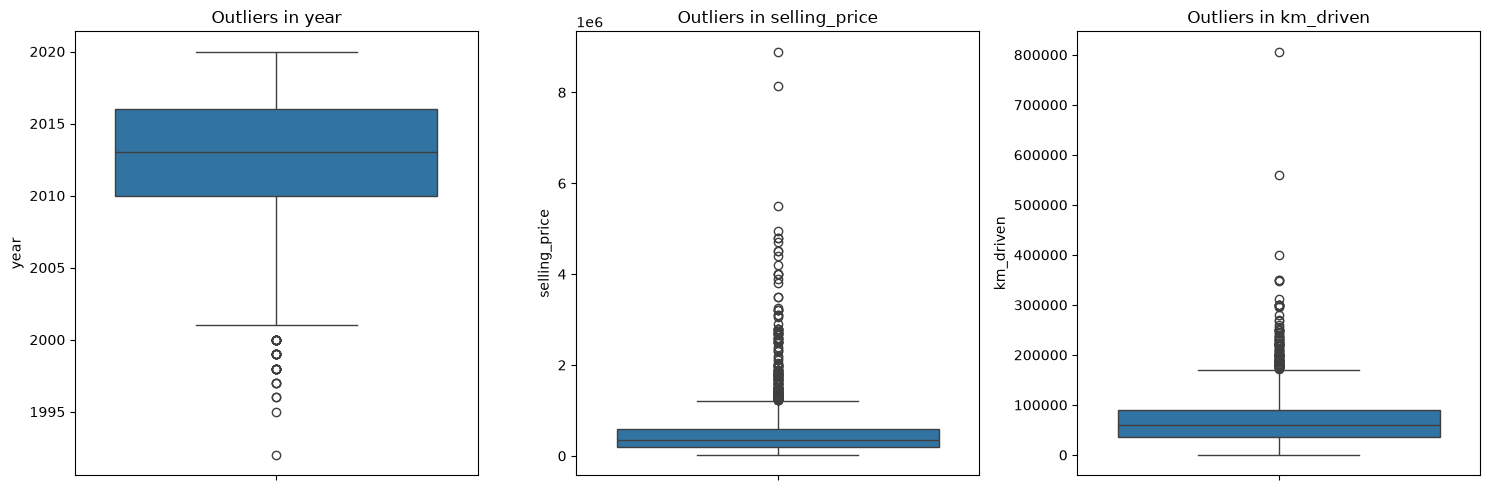

In [56]:
plt.figure(figsize=(15, 5))

for i, col in enumerate(numerical_columns):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=carDataSet[col])
    plt.title(f"Outliers in {col}")

plt.tight_layout()
plt.show()

Boxplots were created for year, selling_price, and km_driven to identify potential outliers. The IQR method detected 37, 170, and 106 outliers respectively. After inspecting the values, all outliers were retained because they may represent genuine car records. No data was removed or modified.

In [57]:
for col in numerical_columns:

    Q1 = carDataSet[col].quantile(0.25)
    Q3 = carDataSet[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = carDataSet[
        (carDataSet[col] < lower_limit) |
        (carDataSet[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Outliers Count:", len(outliers))


Column: year
Lower Limit: 2001.0
Upper Limit: 2025.0
Outliers Count: 37

Column: selling_price
Lower Limit: -400000.0
Upper Limit: 1200000.0
Outliers Count: 170

Column: km_driven
Lower Limit: -45000.0
Upper Limit: 171000.0
Outliers Count: 106


The IQR method was applied to detect outliers in year, selling_price, and km_driven. A total of 37, 170, and 106 outliers were identified respectively. These values were inspected and retained because they may represent genuine vehicle records.

In [58]:
# Check outlier records

for col in ['year', 'selling_price', 'km_driven']:

    Q1 = carDataSet[col].quantile(0.25)
    Q3 = carDataSet[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = carDataSet[
        (carDataSet[col] < lower_limit) |
        (carDataSet[col] > upper_limit)
    ]

    print(f"\nOutliers in {col}:")
    print(outliers[[col]].sort_values(by=col))


Outliers in year:
      year
3334  1992
631   1995
2972  1996
61    1996
1669  1997
3550  1997
3661  1997
1699  1998
3371  1998
3532  1998
2342  1998
2908  1998
2044  1998
1943  1998
3621  1998
137   1998
391   1999
2097  1999
2904  1999
2777  1999
3396  1999
850   1999
1579  1999
1126  1999
3856  1999
1397  2000
1927  2000
1598  2000
372   2000
2560  2000
1404  2000
1184  2000
2635  2000
2495  2000
3889  2000
3984  2000
4325  2000

Outliers in selling_price:
      selling_price
2404        1225000
4228        1225000
2718        1230000
2848        1240000
4049        1249000
...             ...
3453        4800000
555         4950000
3969        5500000
89          8150000
3872        8900000

[170 rows x 1 columns]

Outliers in km_driven:
      km_driven
636      172000
2796     173000
3475     175000
159      175000
3533     175000
...         ...
2394     350000
69       350000
3679     400000
525      560000
1243     806599

[106 rows x 1 columns]


The actual outlier records were inspected to understand unusual values in each numerical column. This helped identify whether the outliers represent genuine vehicle data or incorrect entries. All identified outliers were retained because they appeared to be potentially valid records.

In [60]:
for col in ['year', 'selling_price', 'km_driven']:

    Q1 = carDataSet[col].quantile(0.25)
    Q3 = carDataSet[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = carDataSet[
        (carDataSet[col] < lower) | (carDataSet[col] > upper)
    ]

    print("\n", "="*40)
    print("Column:", col)
    print("Total Outliers:", len(outliers))
    print("Minimum Value:", outliers[col].min())
    print("Maximum Value:", outliers[col].max())

    display(outliers.head(10))


Column: year
Total Outliers: 37
Minimum Value: 1992
Maximum Value: 2000


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
61,Mahindra Jeep CL 500 MDI,1996,250000,35000,Diesel,Individual,Manual,Second Owner
137,Maruti 800 Std,1998,40000,40000,Petrol,Individual,Manual,Fourth & Above Owner
372,Maruti 800 AC,2000,60000,40000,Petrol,Individual,Manual,Third Owner
391,Hyundai Santro GLS I - Euro I,1999,50000,120000,Petrol,Individual,Manual,Second Owner
631,Maruti Gypsy E MG410W ST,1995,95000,100000,Petrol,Individual,Manual,Second Owner
850,Maruti Zen LXI,1999,85000,70000,Petrol,Individual,Manual,Second Owner
1126,Maruti Esteem VX,1999,60000,35000,Petrol,Individual,Manual,Second Owner
1184,Maruti Gypsy King Hard Top,2000,165000,60000,Petrol,Individual,Manual,Fourth & Above Owner
1397,Mahindra Jeep MM 775 XDB,2000,155000,50000,Diesel,Individual,Manual,Second Owner
1404,Maruti 800 DX,2000,50000,60000,Petrol,Individual,Manual,First Owner



Column: selling_price
Total Outliers: 170
Minimum Value: 1225000
Maximum Value: 8900000


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
12,Toyota Corolla Altis 1.8 VL CVT,2018,1650000,25000,Petrol,Dealer,Automatic,First Owner
29,Jaguar XF 2.2 Litre Luxury,2014,1964999,28000,Diesel,Dealer,Automatic,First Owner
30,Mercedes-Benz New C-Class 220 CDI AT,2013,1425000,59000,Diesel,Dealer,Automatic,First Owner
35,Audi A6 2.0 TDI Design Edition,2013,1735000,50000,Diesel,Dealer,Automatic,First Owner
36,Mercedes-Benz New C-Class C 220 CDI Avantgarde,2012,1375000,33800,Diesel,Dealer,Automatic,Second Owner
39,Toyota Innova 2.5 G (Diesel) 7 Seater,2015,1300000,80000,Diesel,Individual,Manual,First Owner
40,Jeep Compass 1.4 Sport Plus BSIV,2019,1400000,10000,Petrol,Individual,Manual,First Owner
43,BMW 3 Series 320d Sport Line,2013,1550000,75800,Diesel,Dealer,Automatic,Second Owner
44,Audi Q7 35 TDI Quattro Premium,2009,1250000,78000,Diesel,Dealer,Automatic,Third Owner
89,Mercedes-Benz S-Class S 350d Connoisseurs Edition,2017,8150000,6500,Diesel,Dealer,Automatic,First Owner



Column: km_driven
Total Outliers: 106
Minimum Value: 172000
Maximum Value: 806599


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
32,Audi Q5 2.0 TDI,2011,1190000,175900,Diesel,Dealer,Automatic,First Owner
69,Chevrolet Tavera Neo LS B3 - 7(C) seats BSIII,2010,280000,350000,Diesel,Individual,Manual,Second Owner
70,Toyota Corolla Altis Diesel D4DG,2011,350000,230000,Diesel,Individual,Manual,First Owner
159,Chevrolet Enjoy 1.3 TCDi LS 8,2015,300000,175000,Diesel,Individual,Manual,First Owner
197,Mahindra Xylo E4,2009,229999,230000,Diesel,Individual,Manual,Third Owner
225,Mahindra Renault Logan 1.5 DLS,2008,89999,213000,Diesel,Individual,Manual,First Owner
269,Maruti Alto LXi,2007,100000,195000,Petrol,Individual,Manual,First Owner
306,Mahindra Bolero Power Plus Plus AC BSIV PS,2015,430000,200000,Diesel,Individual,Manual,First Owner
324,Mahindra XUV500 W8 2WD,2012,850000,212814,Diesel,Dealer,Manual,First Owner
344,Mahindra Bolero SLX,2006,229999,200000,Diesel,Individual,Manual,Third Owner


The outlier records were displayed to inspect the actual unusual values in each numerical column. We checked their minimum and maximum values and reviewed sample car records. This helped confirm that the outliers represent potentially genuine vehicle data, so we retained them.

In [61]:
print("Total Rows:", len(carDataSet))
print("Outliers Retained: Yes")

Total Rows: 3577
Outliers Retained: Yes


We used the IQR method to detect outliers in three numerical columns: year, selling_price, and km_driven. We identified 37 outliers in year, 170 in selling_price, and 106 in km_driven. After inspecting these values, we found that they could represent genuine vehicle records. Therefore, we decided to retain all outliers instead of removing them to preserve useful information.

## Step # 04 Univariate Analysis

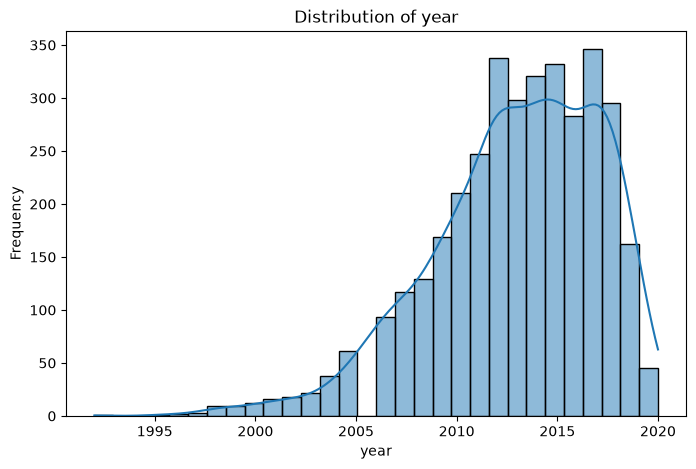

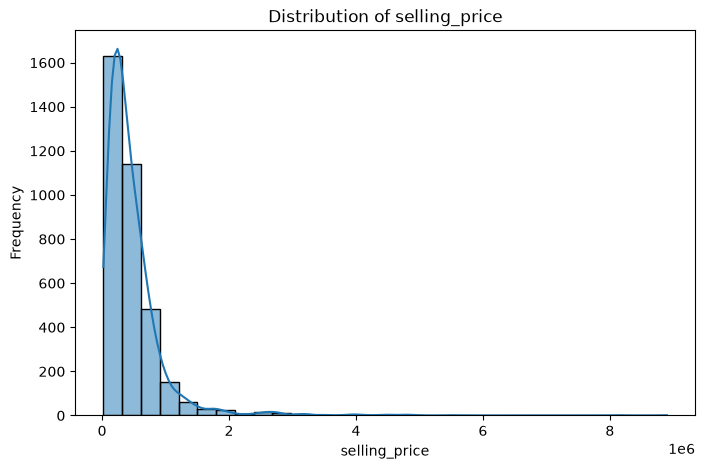

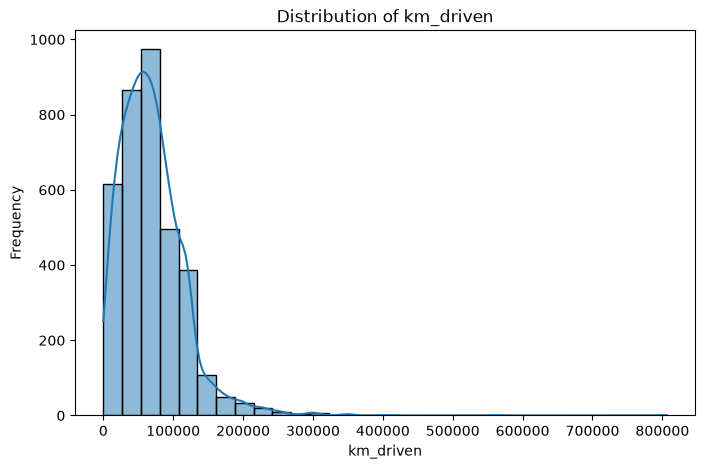

In [ ]:
# Numerical columns: distribution plots
for col in numerical_columns:
    plt.figure(figsize=(8, 5))

    sns.histplot(carDataSet[col], bins=30, kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.show()

1. Year: The histogram shows that most cars belong to model years 2012–2018, while older cars are less frequent. The highest frequency is observed around 2017.

2. Selling Price: The histogram shows a right-skewed distribution, meaning most cars have lower selling prices. Only a few cars have very high selling prices, indicating potential outliers.

3. KM Driven: The histogram shows that most cars have driven between 20,000 and 120,000 km. The distribution is right-skewed, with a few cars having extremely high mileage.

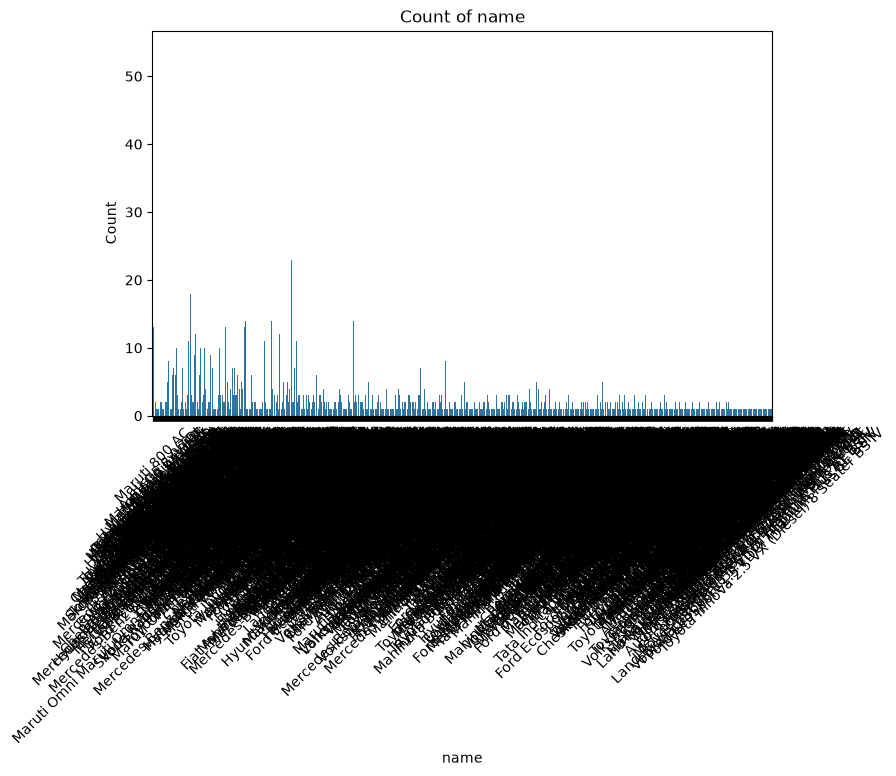

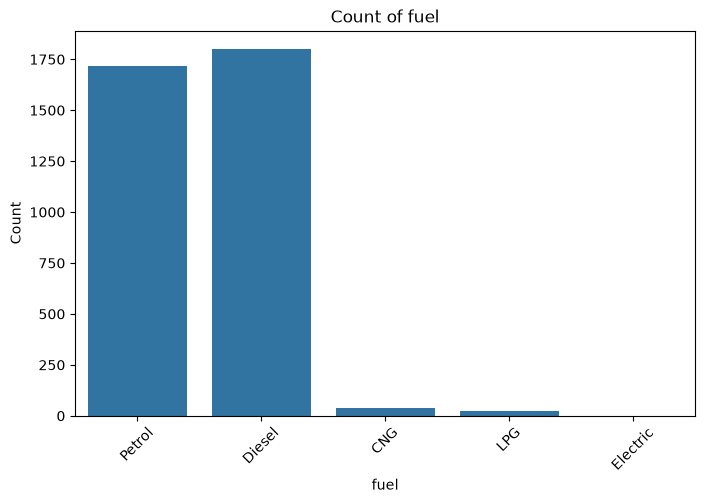

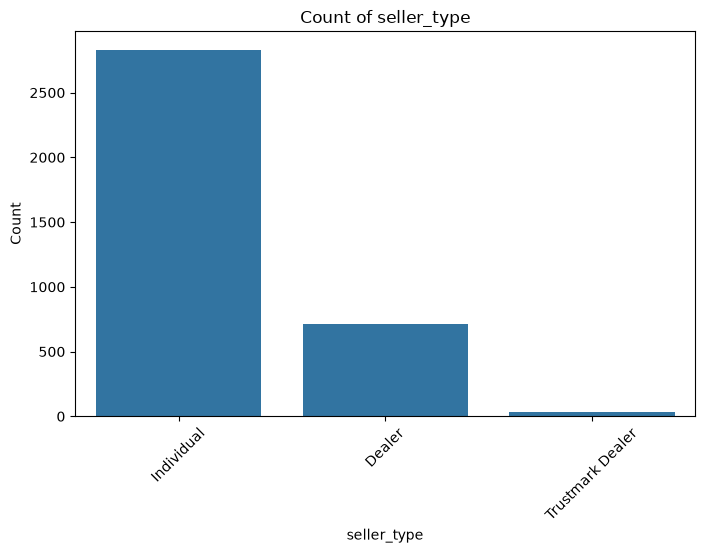

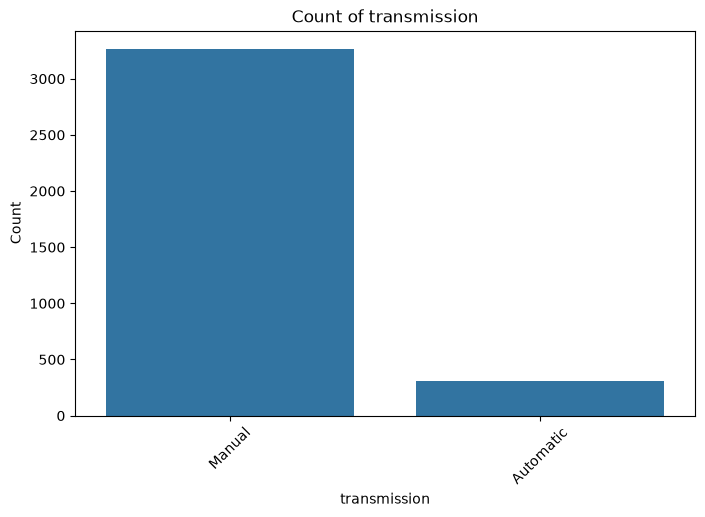

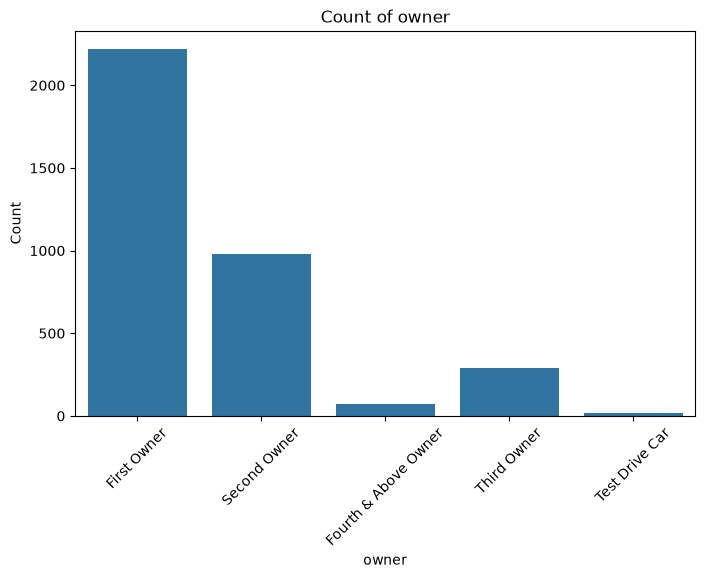

In [ ]:
# Categorical columns: frequency plots
for col in categorical_columns:
    plt.figure(figsize=(8, 5))

    sns.countplot(data=carDataSet, x=col)

    plt.title(f'Count of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

    plt.xticks(rotation=45)
    plt.show()

1. Name: The count plot shows that car models have different frequencies in the dataset. Some car models appear more frequently, while most models have relatively low counts.

2. Fuel: The graph shows that Diesel and Petrol cars dominate the dataset. CNG and LPG cars are very few, while Electric cars are almost absent.

3. Seller Type: The graph shows that most cars are sold by Individual sellers, followed by Dealers. Trustmark Dealers represent the smallest category.

4. Transmission: The count plot shows that Manual transmission cars dominate the dataset, while Automatic transmission cars are significantly fewer.

5. Owner: The graph shows that First Owner cars have the highest count, followed by Second Owner cars. Third Owner and Fourth & Above Owner cars are much fewer, while Test Drive Cars represent the smallest category.

## Step 05: Bivariate Analysis

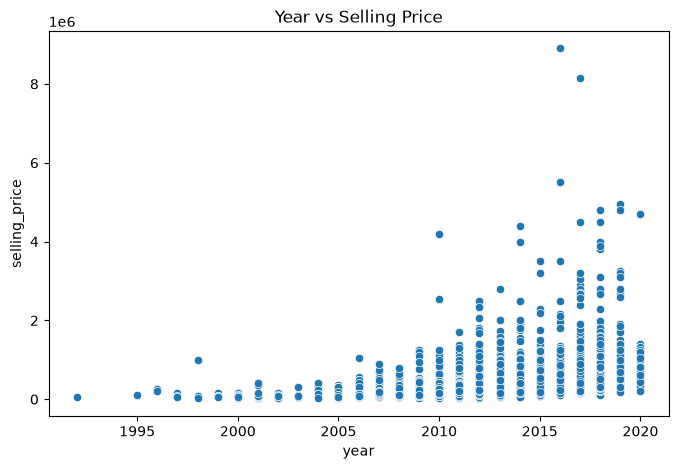

In [67]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=carDataSet,
    x='year',
    y='selling_price'
)

plt.title('Year vs Selling Price')
plt.show()

Scatter Plot (Year vs Selling Price): Shows the relationship between car manufacturing year and selling price. Newer cars generally have higher selling prices.

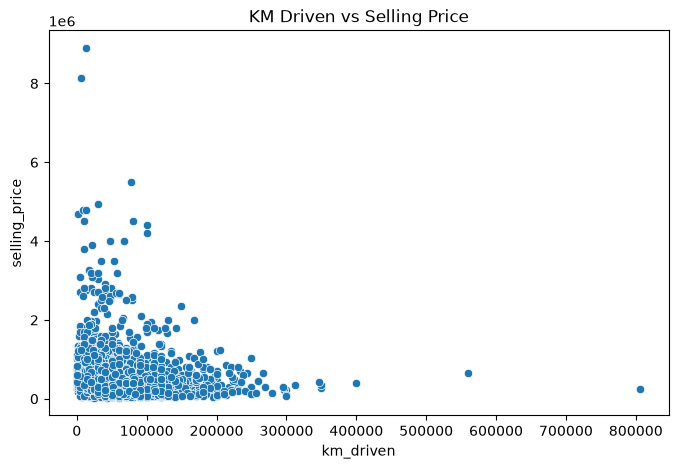

In [68]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=carDataSet,
    x='km_driven',
    y='selling_price'
)

plt.title('KM Driven vs Selling Price')
plt.show()

Scatter Plot (KM Driven vs Selling Price): Shows the relationship between kilometers driven and selling price. Generally, cars with higher mileage have lower selling prices.

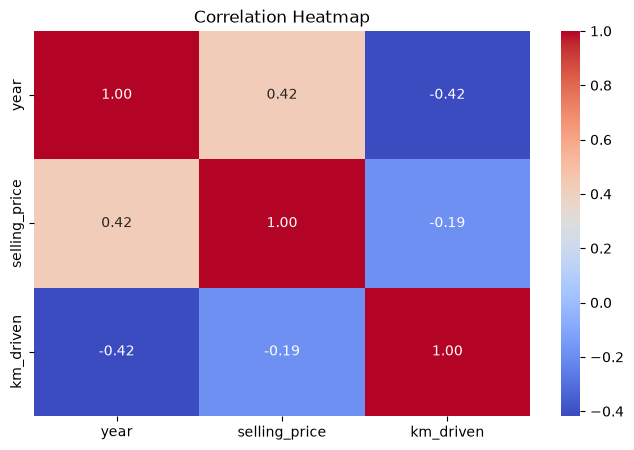

In [69]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    carDataSet[['year', 'selling_price', 'km_driven']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

Correlation Heatmap: Shows the correlation between numerical columns. Year has a positive correlation (0.42) with selling price, while KM driven has a negative correlation (-0.19) with selling price.

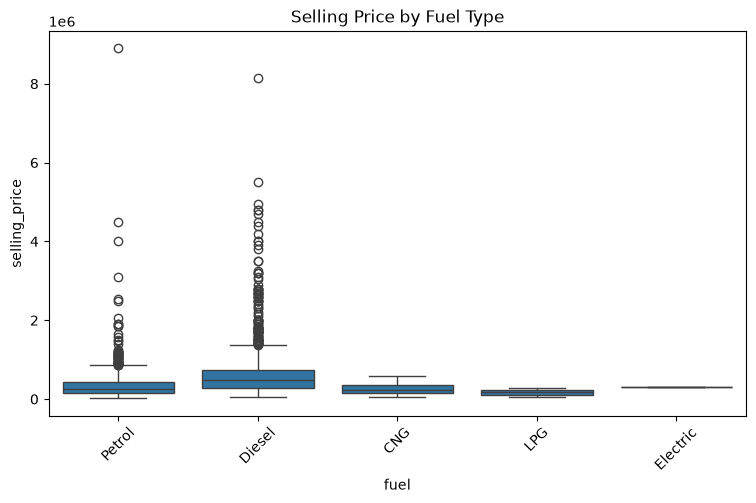

In [70]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=carDataSet,
    x='fuel',
    y='selling_price'
)

plt.title('Selling Price by Fuel Type')
plt.xticks(rotation=45)
plt.show()

Selling Price by Fuel Type:

This box plot shows the comparison of car selling prices based on fuel type. Diesel cars generally have higher selling prices than petrol cars, while CNG and LPG cars have comparatively lower prices. Several outliers indicate some cars have exceptionally high selling prices.

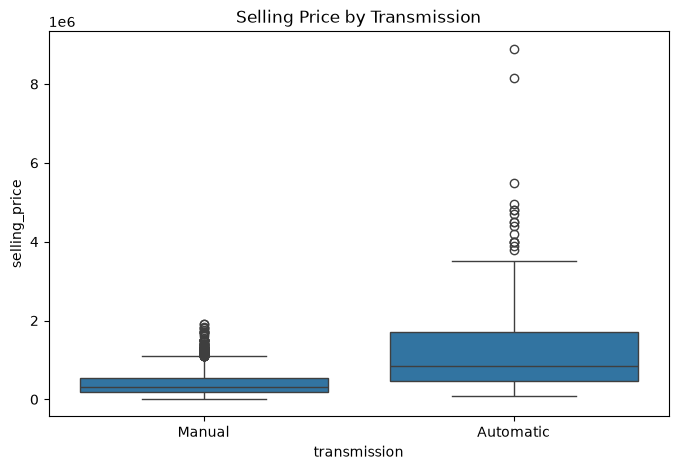

In [71]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=carDataSet,
    x='transmission',
    y='selling_price'
)

plt.title('Selling Price by Transmission')
plt.show()

Selling Price by Transmission:

This box plot compares car selling prices based on transmission type. Automatic cars generally have higher selling prices than manual cars. Automatic cars also show greater price variation, while manual cars have comparatively lower prices and fewer extreme outliers.

## Step 6: Answer your questions


### Univariate Analysis
**Q1. Which car models appear most frequently in the dataset?**

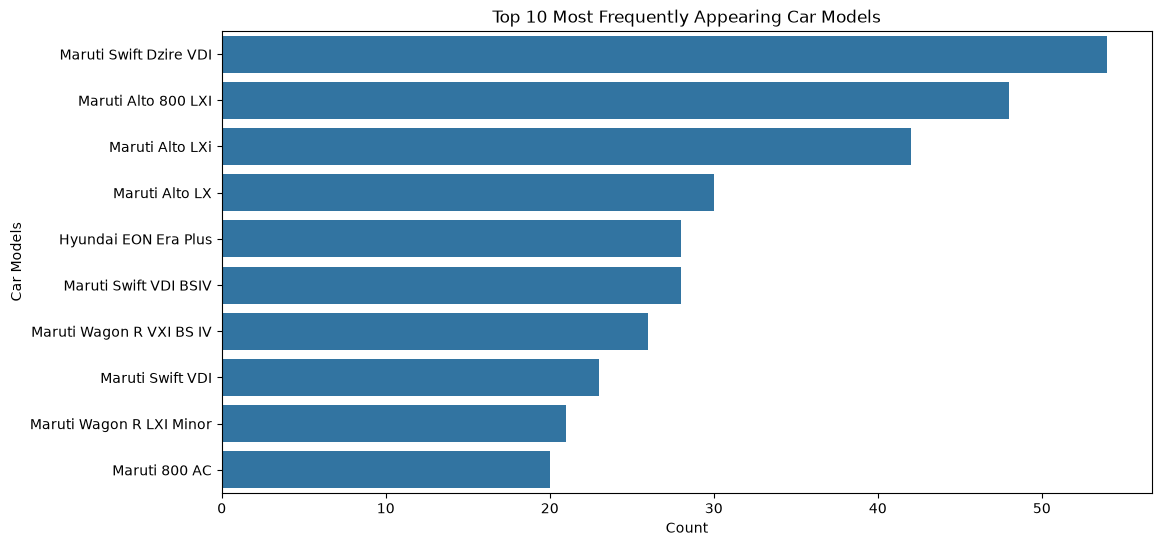

In [95]:
top_cars = carDataSet['name'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_cars.values, y=top_cars.index)

plt.title('Top 10 Most Frequently Appearing Car Models')
plt.xlabel('Count')
plt.ylabel('Car Models')
plt.show()

The bar chart shows the frequency of different car models in the dataset. **Maruti Swift Dzire VDI** appears most frequently, followed by **Maruti Alto 800 LXI** and **Maruti Alto LXi**. This helps identify the most commonly available car models in the dataset.

**Q2. Which fuel type is most commonly used?**

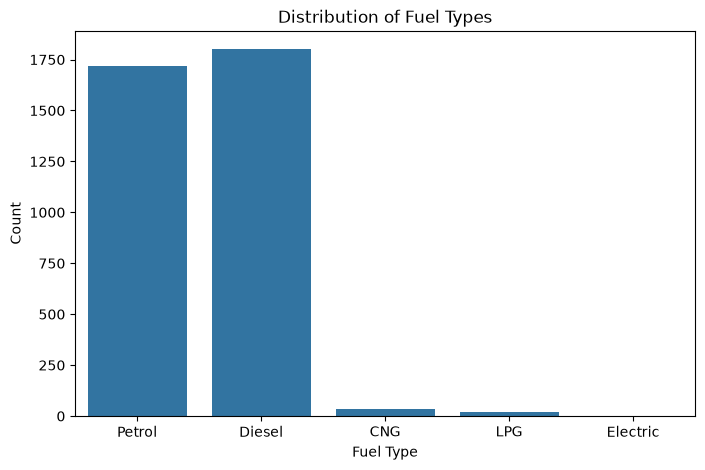

In [96]:
plt.figure(figsize=(8, 5))

sns.countplot(data=carDataSet, x='fuel')

plt.title('Distribution of Fuel Types')
plt.xlabel('Fuel Type')
plt.ylabel('Count')
plt.show()

The bar chart shows the distribution of different fuel types in the dataset. **Diesel and Petrol** are the most commonly used fuel types, with Diesel having a slightly higher count than Petrol. CNG and LPG are used much less, while Electric cars are almost negligible.

**Q3. Which transmission type is most popular?**

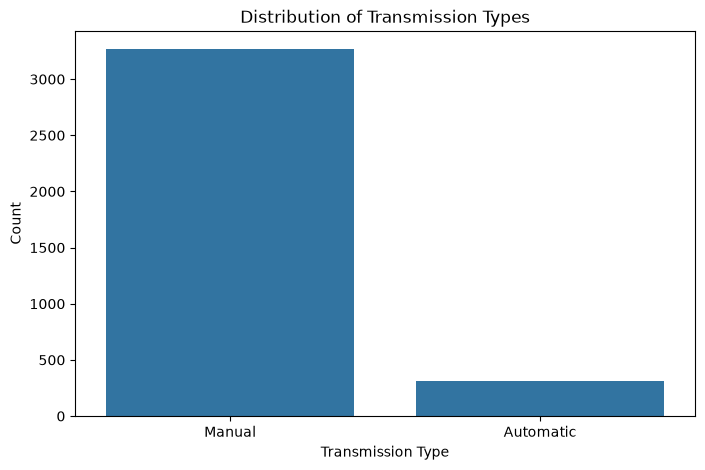

In [97]:
plt.figure(figsize=(8, 5))

sns.countplot(data=carDataSet, x='transmission')

plt.title('Distribution of Transmission Types')
plt.xlabel('Transmission Type')
plt.ylabel('Count')
plt.show()

The count plot shows that Manual transmission cars dominate the dataset, while Automatic transmission cars are significantly fewer. This indicates that Manual transmission is the most popular transmission type in the dataset.

### Bivariate Analysis
**Q4. How is manufacturing year associated with car selling prices?**

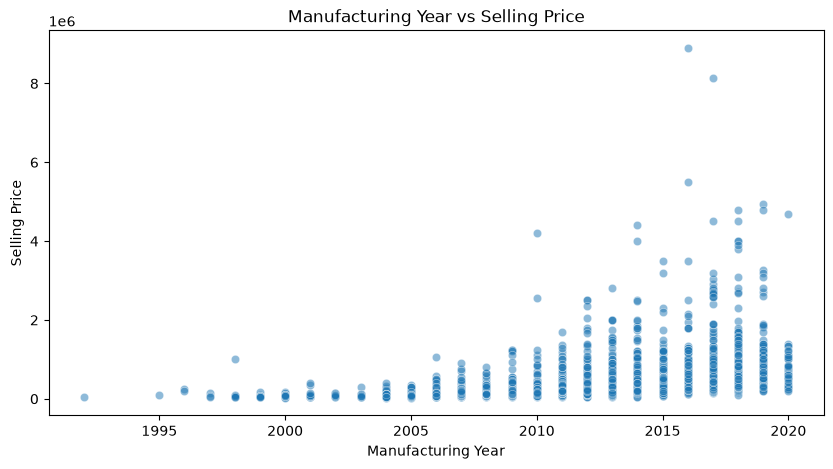

In [98]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=carDataSet,
    x='year',
    y='selling_price',
    alpha=0.5
)

plt.title('Manufacturing Year vs Selling Price')
plt.xlabel('Manufacturing Year')
plt.ylabel('Selling Price')
plt.show()

The scatter plot shows the relationship between the manufacturing year and selling price of cars. It helps us understand how car prices vary according to their manufacturing years. Newer cars generally tend to have higher selling prices compared to older cars.

**Q5. Is there a relationship between kilometers driven and selling price?**

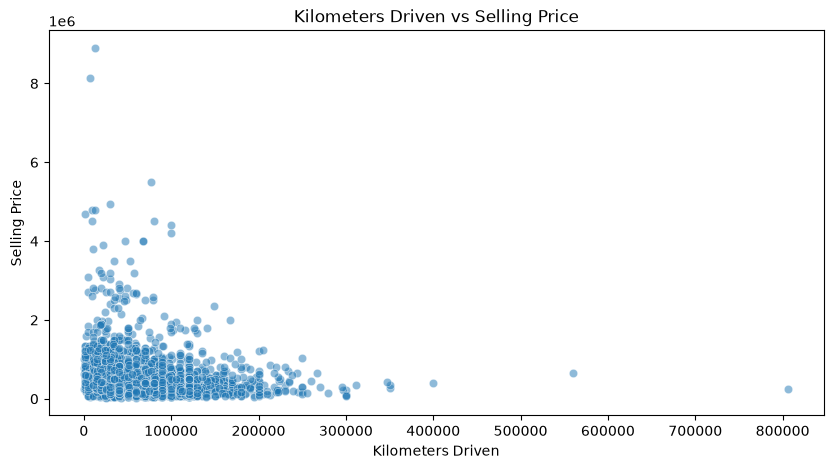

In [99]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=carDataSet,
    x='km_driven',
    y='selling_price',
    alpha=0.5
)

plt.title('Kilometers Driven vs Selling Price')
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price')
plt.show()

The scatter plot shows the relationship between kilometers driven and selling price. It helps us understand how the usage of a car affects its market value. Cars driven for more kilometers generally tend to have lower selling prices compared to cars driven for fewer kilometers.

**Q6. Which fuel type has the highest average selling price?**

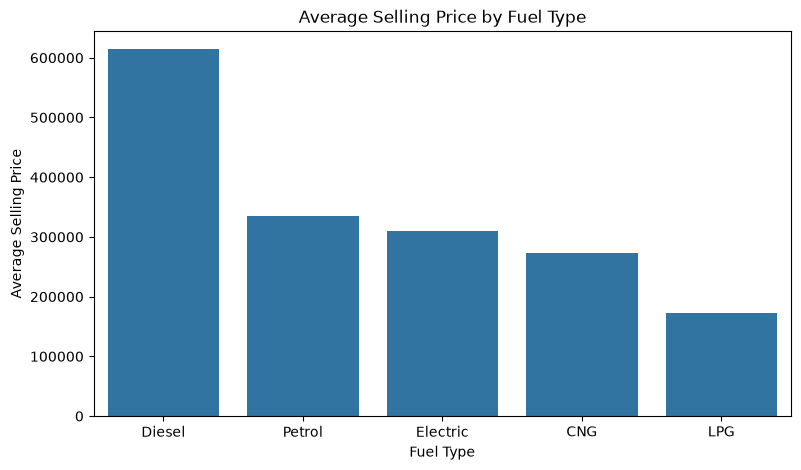

In [100]:
fuel_prices = carDataSet.groupby('fuel')['selling_price'].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(x=fuel_prices.index, y=fuel_prices.values)

plt.title('Average Selling Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Average Selling Price')
plt.show()

The bar chart compares the average selling price of cars across different fuel types. Diesel cars have the highest average selling price, followed by Petrol and Electric cars, while LPG cars have the lowest average selling price. This shows that fuel type can be associated with differences in car selling prices.

### Group Comparison
**Q7. How does selling price differ between first-owner and second-owner cars?**

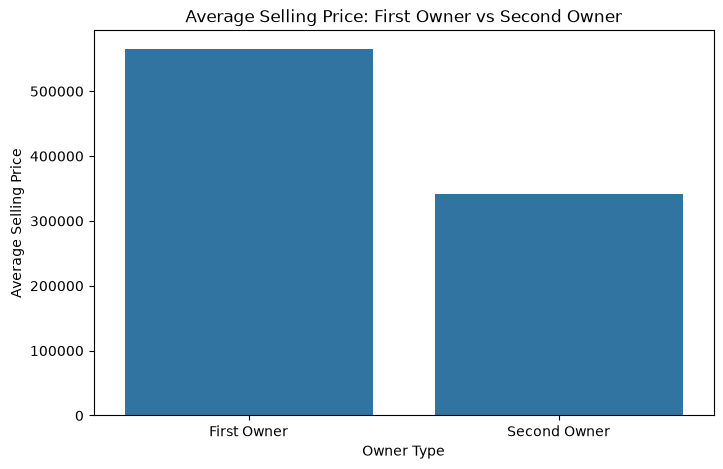

In [101]:
owner_data = carDataSet[
    carDataSet['owner'].isin(['First Owner', 'Second Owner'])
]

owner_prices = owner_data.groupby('owner')['selling_price'].mean()

plt.figure(figsize=(8, 5))

sns.barplot(x=owner_prices.index, y=owner_prices.values)

plt.title('Average Selling Price: First Owner vs Second Owner')
plt.xlabel('Owner Type')
plt.ylabel('Average Selling Price')
plt.show()

The bar chart compares the average selling prices of cars based on ownership type. First-owner cars have a higher average selling price (around 600,000) compared to second-owner cars (around 345,000). This indicates that cars with fewer previous owners generally have a higher resale value.

**Q8. Do automatic cars have higher average selling prices than manual cars?**

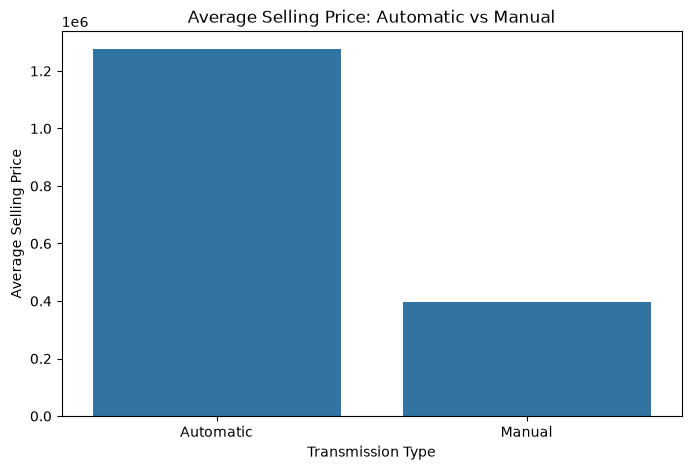

In [102]:
transmission_prices = carDataSet.groupby('transmission')['selling_price'].mean()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=transmission_prices.index,
    y=transmission_prices.values
)

plt.title('Average Selling Price: Automatic vs Manual')
plt.xlabel('Transmission Type')
plt.ylabel('Average Selling Price')
plt.show()

The bar chart compares the average selling prices of cars based on transmission type. Automatic cars have a significantly higher average selling price (around 1.4 million) compared to manual cars (around 400,000). This indicates that automatic transmission cars are generally more expensive than manual cars.

# Step 7: Conclusion

After performing Exploratory Data Analysis (EDA) on the Car Dataset, we identified several important patterns and insights related to car models, fuel types, transmission, ownership, and selling prices.

## 1. Main Findings

**1. Car Models and Fuel Types**

The dataset contains various car models with different frequencies. Some models appear more frequently than others. Diesel and Petrol are the most common fuel types, while CNG, LPG, and Electric cars represent a smaller portion of the dataset.

**2. Transmission and Ownership**

Manual transmission cars are significantly more common than Automatic cars. Similarly, most vehicles belong to first-time owners, followed by second-time owners. Cars with multiple previous owners are relatively less common.

**3. Factors Affecting Selling Prices**

The analysis explores the relationship between manufacturing year, kilometers driven, fuel type, ownership, and selling price. Generally, newer cars tend to have higher selling prices, while cars driven for more kilometers tend to have lower selling prices.

## 2. Actionable Suggestion

Based on the analysis, car buyers should carefully compare the manufacturing year, kilometers driven, fuel type, transmission type, and ownership history before purchasing a used car.

Sellers can also consider these factors when setting competitive prices for their vehicles to attract potential buyers.

## Final Summary

This EDA project helped us understand the distribution of cars, identify common vehicle characteristics, explore relationships between different variables, and gain useful insights into used car selling prices.